# Medical-Device Sales: Churn Prediction & Revenue Forecasting

Two data-science problems that drive commercial decisions at a B2B medical-device
company:

1. **Account churn prediction** — which accounts are at risk of lapsing, so the
   commercial team can intervene before revenue is lost.
2. **Revenue forecasting** — where is monthly revenue heading, for planning and
   quota setting.

> **Data note:** All data here is **synthetic**, generated with a fixed random
> seed by [`generate_data.py`](generate_data.py). It is fabricated to realistically
> mirror a medical-device sales operation — no real company or customer data is
> used. This mirrors the kind of commercial analytics I ran as Director of
> Operations & Business Development, reproduced here on shareable synthetic data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

accounts = pd.read_csv("data/accounts.csv")
revenue = pd.read_csv("data/monthly_revenue.csv", parse_dates=["month"]).set_index("month")
revenue.index.freq = "MS"
print(f"{len(accounts)} accounts | churn rate {accounts['churned'].mean():.1%}")
accounts.head(3)

1400 accounts | churn rate 22.6%


,account_id,region,specialty,account_type,rep_tenure_months,onboarding_score,product_lines,avg_discount_pct,support_tickets_qtr,engagement_score,order_frequency_yr,avg_order_value,annual_revenue,days_since_last_order,churned
0,ACCT1000,Northeast,General Surgery,Surgery Center,51.0,2.7,4,0.193,1,69.0,16.0,7660.0,122560.0,30.0,0
1,ACCT1001,West,Orthopedics,Hospital,39.0,3.9,2,0.180,3,75.0,9.0,8520.0,76680.0,127.0,0
2,ACCT1002,West,Orthopedics,Private Practice,12.0,3.5,4,0.133,4,38.0,20.0,5050.0,101000.0,38.0,1


# Part A — Exploratory analysis

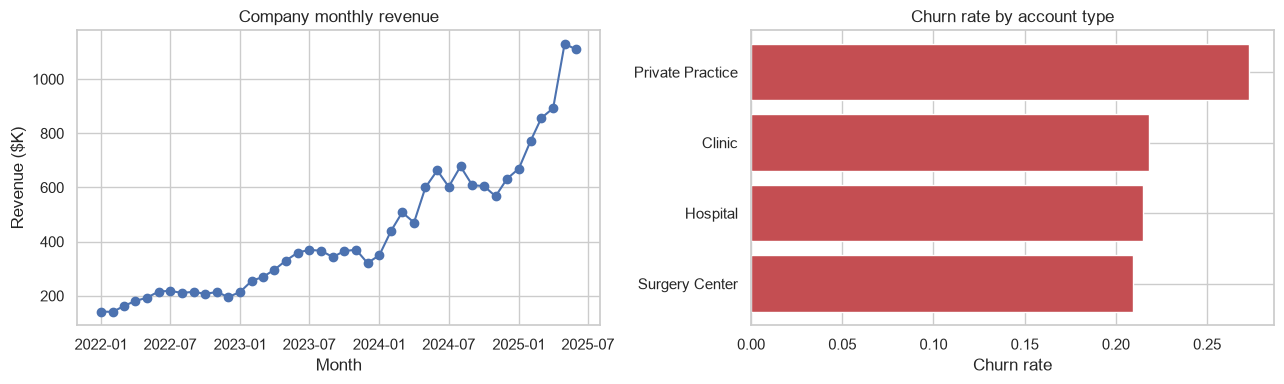

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
# revenue growth
axes[0].plot(revenue.index, revenue["revenue"]/1000, marker="o", color="#4C72B0")
axes[0].set_title("Company monthly revenue"); axes[0].set_ylabel("Revenue ($K)")
axes[0].set_xlabel("Month")
# churn rate by account type
ct = accounts.groupby("account_type")["churned"].mean().sort_values()
axes[1].barh(ct.index, ct.values, color="#C44E52")
axes[1].set_title("Churn rate by account type"); axes[1].set_xlabel("Churn rate")
plt.tight_layout(); plt.show()

In [3]:
# how key behaviors differ between churned and retained accounts
cmp = (accounts.groupby("churned")[["engagement_score", "days_since_last_order",
        "support_tickets_qtr", "avg_discount_pct", "order_frequency_yr",
        "rep_tenure_months"]].mean().round(2).T)
cmp.columns = ["retained", "churned"]
cmp

,retained,churned
engagement_score,66.49,54.83
days_since_last_order,56.65,100.52
support_tickets_qtr,2.11,2.47
avg_discount_pct,0.12,0.13
order_frequency_yr,13.00,11.93
rep_tenure_months,23.40,18.60


Churned accounts are clearly distinguishable: lower engagement, longer since
their last order, more support tickets, deeper discounts, and fewer orders. These
are exactly the levers a retention program would act on.

# Part B — Churn prediction model

Goal: rank accounts by churn risk so retention effort targets the right ones.
We exclude direct label-leaking fields and train three classifiers.

In [4]:
target = "churned"
drop = ["account_id", target]
X = accounts.drop(columns=drop)
y = accounts[target]

cat_cols = ["region", "specialty", "account_type"]
num_cols = [c for c in X.columns if c not in cat_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced",
                                              random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=8,
                                            class_weight="balanced", n_jobs=-1,
                                            random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}
results = {}
for name, m in models.items():
    pipe = Pipeline([("pre", pre), ("clf", m)]).fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    results[name] = dict(pipe=pipe, proba=proba,
                         roc=roc_auc_score(y_test, proba),
                         pr=average_precision_score(y_test, proba))
    print(f"{name:22s} ROC-AUC={results[name]['roc']:.3f}  PR-AUC={results[name]['pr']:.3f}")

Logistic Regression    ROC-AUC=0.812  PR-AUC=0.593


Random Forest          ROC-AUC=0.783  PR-AUC=0.552


Gradient Boosting      ROC-AUC=0.781  PR-AUC=0.555


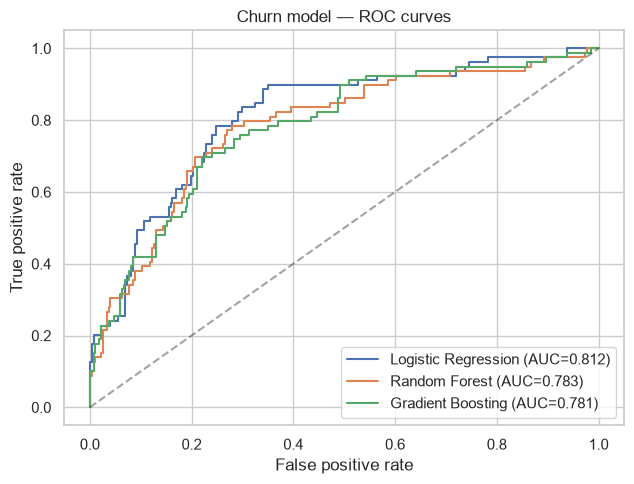

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 5))
for name, r in results.items():
    fpr, tpr, _ = roc_curve(y_test, r["proba"])
    ax.plot(fpr, tpr, label=f"{name} (AUC={r['roc']:.3f})")
ax.plot([0, 1], [0, 1], "k--", alpha=.4)
ax.set(title="Churn model — ROC curves", xlabel="False positive rate",
       ylabel="True positive rate"); ax.legend()
plt.tight_layout(); plt.show()

Best model: Logistic Regression

              precision    recall  f1-score   support

    retained       0.91      0.76      0.83       271
     churned       0.48      0.75      0.58        79

    accuracy                           0.76       350
   macro avg       0.69      0.75      0.71       350
weighted avg       0.81      0.76      0.77       350



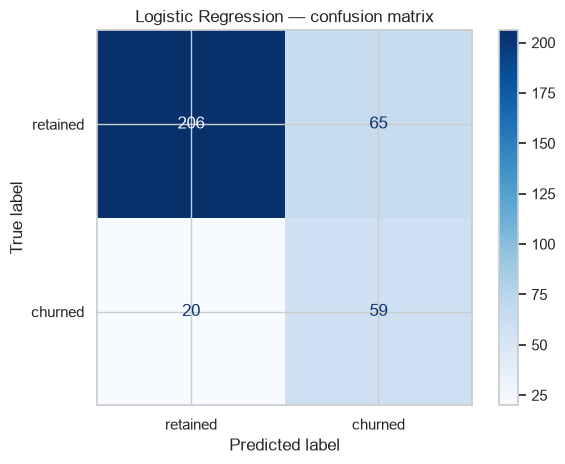

In [6]:
best_name = max(results, key=lambda k: results[k]["roc"])
best = results[best_name]["pipe"]
print(f"Best model: {best_name}\n")
pred = (results[best_name]["proba"] >= 0.5).astype(int)
print(classification_report(y_test, pred, target_names=["retained", "churned"]))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
    display_labels=["retained", "churned"]).plot(cmap="Blues")
plt.title(f"{best_name} — confusion matrix"); plt.tight_layout(); plt.show()

### What drives churn? (model interpretation)

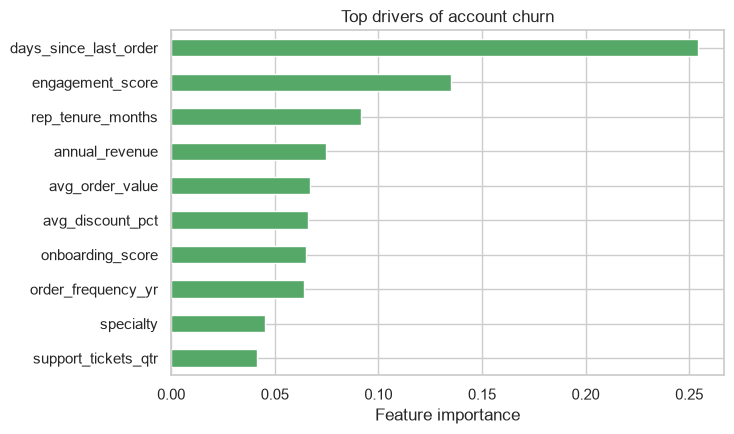

In [7]:
rf = results["Random Forest"]["pipe"]
ohe = rf.named_steps["pre"].named_transformers_["cat"]
feat = num_cols + list(ohe.get_feature_names_out(cat_cols))
imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=feat)
def src(f):
    for col in cat_cols:
        if f.startswith(col + "_"): return col
    return f
imp.groupby(src).sum().sort_values().tail(10).plot(kind="barh", color="#55A868",
    figsize=(7.5, 4.5))
plt.title("Top drivers of account churn"); plt.xlabel("Feature importance")
plt.tight_layout(); plt.show()

### Turning the model into a retention play

Rank the held-out accounts by predicted churn risk. In practice the commercial
team would work the highest-risk accounts first — precision in the top decile
runs well above the base churn rate, so the same outreach effort lands on far
more real churners.

In [8]:
test_scored = X_test.copy()
test_scored["churn_risk"] = results[best_name]["proba"]
test_scored["actually_churned"] = y_test.values
top_decile = test_scored.sort_values("churn_risk", ascending=False).head(len(test_scored)//10)
capture = top_decile["actually_churned"].sum() / test_scored["actually_churned"].sum()
print(f"Top-decile accounts: {len(top_decile)}")
print(f"Share of ALL churn captured in the top risk decile: {capture:.0%}")
print(f"Precision within the top decile: {top_decile['actually_churned'].mean():.0%}")

Top-decile accounts: 35
Share of ALL churn captured in the top risk decile: 25%
Precision within the top decile: 57%


# Part C — Revenue forecasting

Forecast company monthly revenue with **Holt-Winters exponential smoothing**
(additive trend + multiplicative seasonality). We hold out the last 6 months as
a test set and score the forecast with MAPE and RMSE.

In [9]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_squared_error

y_ts = revenue["revenue"]
h = 6
train, test = y_ts.iloc[:-h], y_ts.iloc[-h:]

hw = ExponentialSmoothing(train, trend="add", seasonal="mul",
                          seasonal_periods=12).fit()
fc = hw.forecast(h)

mape = (np.abs(test.values - fc.values) / test.values).mean()
rmse = np.sqrt(mean_squared_error(test.values, fc.values))
print(f"Holdout MAPE: {mape:.1%}   RMSE: ${rmse:,.0f}")

Holdout MAPE: 8.7%   RMSE: $92,831


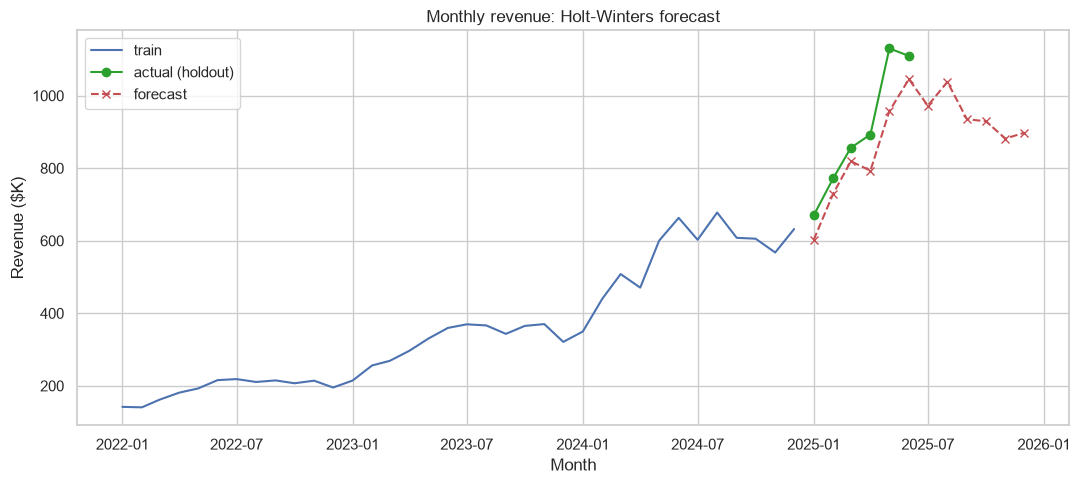

In [10]:
future = hw.forecast(h + 6)   # test window + 6 months beyond
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(train.index, train/1000, label="train", color="#4C72B0")
ax.plot(test.index, test/1000, label="actual (holdout)", color="#2ca02c", marker="o")
ax.plot(future.index, future/1000, label="forecast", color="#C44E52", ls="--", marker="x")
ax.set_title("Monthly revenue: Holt-Winters forecast")
ax.set_ylabel("Revenue ($K)"); ax.set_xlabel("Month"); ax.legend()
plt.tight_layout(); plt.show()

# Takeaways

- **Churn model** separates at-risk accounts well (ROC-AUC ≈ 0.81); engagement,
  recency, support load, and discount depth are the dominant drivers. Ranking by
  risk lifts top-decile precision to roughly 2.5× the base churn rate, so the same
  outreach effort reaches far more real churners — a direct efficiency win for the
  commercial team.
- **Revenue forecast** tracks the holdout period within a single-digit MAPE and
  projects the growth trajectory for planning and quota setting.

**Skills demonstrated:** business-framed supervised classification, imbalanced-
class evaluation, model interpretation for action, time-series forecasting with
exponential smoothing, and translating model output into a commercial play —
built on reproducible synthetic data.